# Zonal means of ocean heat uptake

The data shown in `OHC_plots.ipynb`, resolved by latitude. Plotting and loading functions live in `ohc_cases.py`.

**Conventions.** Data run 2035–2069. OHC change per latitude band is the **2069 annual mean minus the 2035 annual
mean**, the same change as the end point of the time series in `OHC_plots.ipynb` figure 1, so the bands of each
condition add up to that figure's end label (checked below). Annual means weight each month by its length;
ensembles are member means. Bands are 5° wide and are built on the native POP grid: every ocean cell's heat
content per m² times its area, summed over the cells whose T-point latitude falls in the band (no regridding).
Each member's bands are checked to sum to the change in its `OHC_global_mean` × ocean area. Units are ZJ (10²¹ J)
per band, so a band's value is the total heat it gained, not a per-area density.

In [2]:
# %load_ext autoreload
# %autoreload 2   # pick up edits to ohc_cases.py without restarting the kernel

import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import ohc_cases as oc

plt.rcParams.update(oc.STYLE)

START, END = 2035, 2069
ZONAL_BASE, ZONAL_FINAL = (START, START), (END, END)  # change = mean over ZONAL_FINAL minus mean over ZONAL_BASE;
                                                      # (2035, 2039), (2065, 2069) gives the scatter-plot periods
LAT_EDGES = np.arange(-90, 91, 5)                     # 5° latitude bands

ARISE_CONDITIONS = {      # display name: (family, experiment), as in OHC_plots.ipynb
    "SSP2-4.5": ("CESM2_WACCM_SSP2-4.5", "CMIP6-SSP2-4.5-WACCM"),
    "ARISE-1.5": ("ARISE_SAI", "SSP245-TSMLT-GAUSS-DEFAULT"),
    "ARISE-1.0": ("ARISE-1.0", "SSP245-TSMLT-GAUSS-LOWER-0.5"),
}

In [3]:
# Members and global time series exactly as in OHC_plots.ipynb (duplicates dropped by load_experiments), then the
# latitude-band change for every member.
cases = oc.discover_cases()
labels = cases.experiment.map(oc.experiment_label)
cases = cases[[(f, l) in set(ARISE_CONDITIONS.values()) for f, l in zip(cases.family, labels)]]
experiments = oc.load_experiments(cases, depth=None)
area_m2 = oc.ocean_cell_area_m2()

data = {}
for name, (family, label) in ARISE_CONDITIONS.items():
    key = oc.find_experiment(experiments, family, label)
    zonal = oc.zonal_band_change(cases, experiments, key, ZONAL_BASE, ZONAL_FINAL, edges=LAT_EDGES, area_m2=area_m2)
    data[name] = dict(key=key, ohc=oc.change_since(experiments[key], START, END), zonal=zonal)

## 1. Ocean heat uptake by latitude and depth layer: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Figure 1 of `OHC_plots.ipynb` turned on its side. For each 5° latitude band, the total OHC gained from 2035 to
2069 (black outline) with the part held in each depth layer as stacked bars; layers that lose heat stack left of
zero. Gray outlines are the members' min–max of the band total. The three panels share both axes.

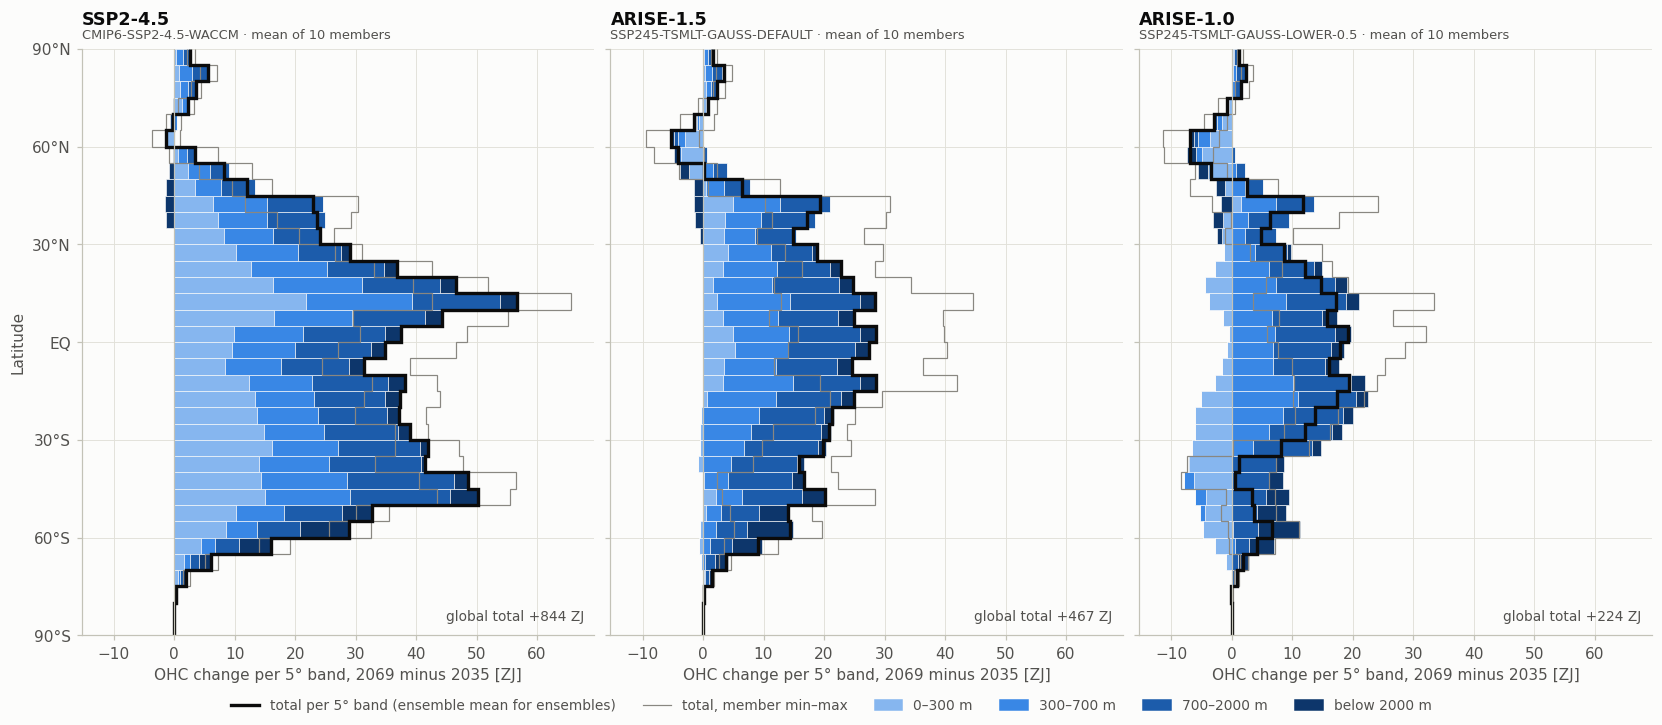

In [4]:
period = f"{ZONAL_FINAL[0]}" if ZONAL_FINAL[0] == ZONAL_FINAL[1] else f"{ZONAL_FINAL[0]}–{ZONAL_FINAL[1]}"
since = f"{ZONAL_BASE[0]}" if ZONAL_BASE[0] == ZONAL_BASE[1] else f"{ZONAL_BASE[0]}–{ZONAL_BASE[1]}"
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
oc.plot_zonal_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["zonal"]) for name in ARISE_CONDITIONS],
                         xlabel=f"OHC change per 5° band, {period} minus {since} [ZJ]")
plt.show()

**Check and hemispheric split.** The band total summed over latitude, against the end point of `OHC_plots.ipynb`
figure 1 (the global time series, ensemble mean, change since 2035), and the share gained in each hemisphere.

In [5]:
rows = {}
for name, d in data.items():
    z = d["zonal"].mean("member") / oc.ZJ
    total = z.sel(ohc_depth=-1)
    rows[name] = {
        "members": d["zonal"].sizes["member"],
        "Σ bands [ZJ]": float(total.sum("lat")),
        f"figure 1 end, {END} since {START} [ZJ]": float(d["ohc"].sel(ohc_depth=-1, year=END).mean()) / oc.ZJ,
        "NH [ZJ]": float(total.where(total.lat > 0).sum()),
        "SH [ZJ]": float(total.where(total.lat < 0).sum()),
        "worst band-sum mismatch": d["zonal"].attrs["max_relative_mismatch"],
    }
check = pd.DataFrame(rows).T.astype({"members": int})
display(check.style.format("{:+.1f}", subset=[c for c in check if "ZJ" in c])
        .format("{:.1e}", subset=["worst band-sum mismatch"]))

,members,Σ bands [ZJ],"figure 1 end, 2069 since 2035 [ZJ]",NH [ZJ],SH [ZJ],worst band-sum mismatch
SSP2-4.5,10,+844.0,+844.0,+358.1,+485.9,1.4e-14
ARISE-1.5,10,+467.0,+467.0,+203.9,+263.1,1.8e-13
ARISE-1.0,10,+224.1,+224.1,+97.4,+126.7,1.2e-12


## 2. Ocean-mean heat uptake by latitude and depth layer: SSP2-4.5, ARISE-1.5 and ARISE-1.0

Figure 1 divided by each band's ocean area: the zonal mean over ocean only (land excluded), in GJ m⁻² (10⁹ J per
m² of ocean surface). Where figure 1 is dominated by the wide, ocean-rich tropical and Southern Ocean bands, this
shows how much heat each m² of ocean took up. Bands with little ocean (the Arctic, 65–80°S) rest on few cells and are
noisier. The corner note is the global ocean mean (global total / ocean area), which equals the band values averaged
with ocean-area weights.

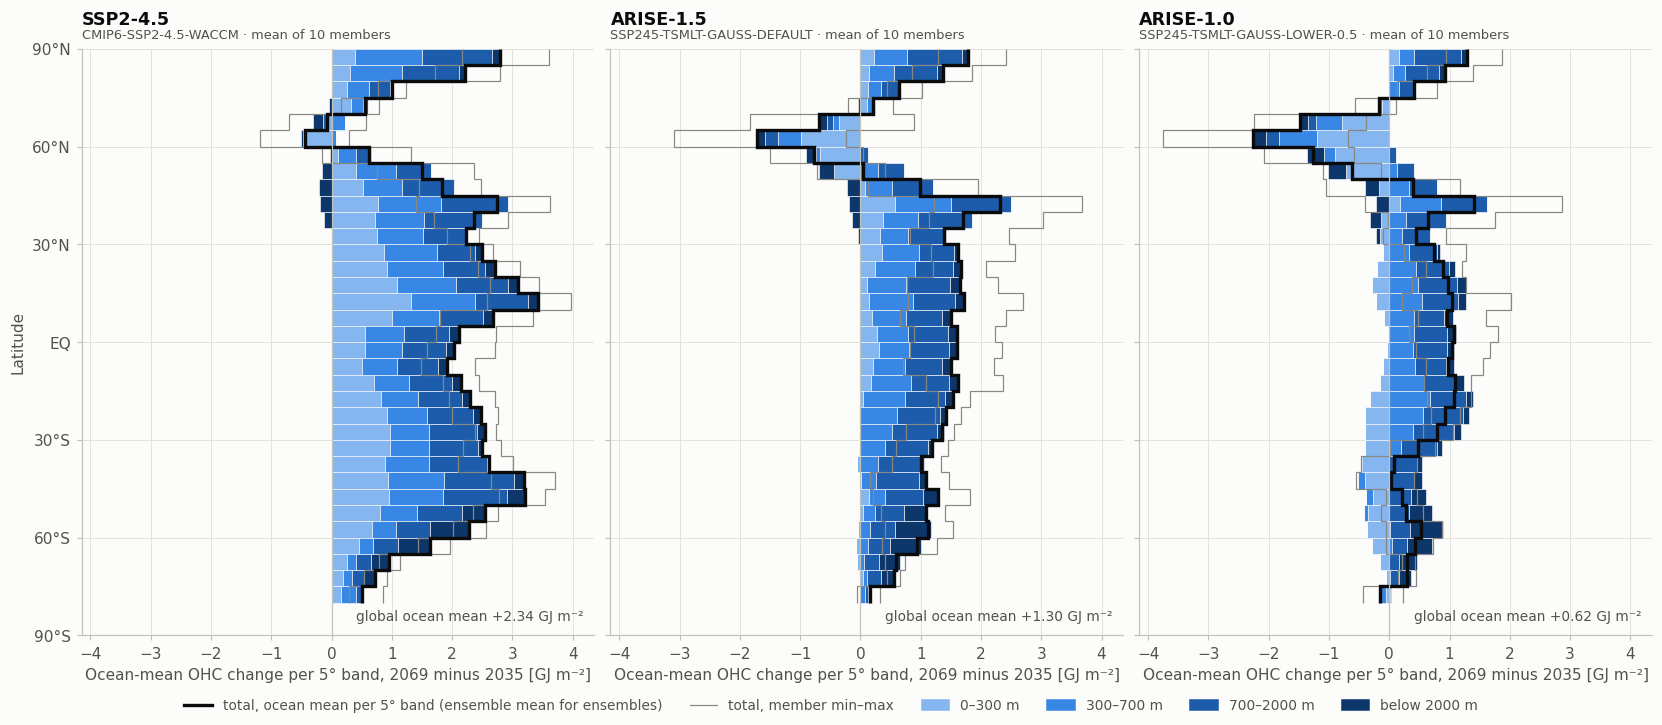

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharex=True, sharey=True, layout="constrained")
oc.plot_zonal_layer_grid(fig, axes, [(name, data[name]["key"], data[name]["zonal"]) for name in ARISE_CONDITIONS],
                         xlabel=f"Ocean-mean OHC change per 5° band, {period} minus {since} [GJ m⁻²]", per_area=True)
plt.show()

**Radiative fluxes (ASR, OLR, EEI, iEEI).** `J04_CESM_EEI_timeseries_multiensemble.py` reads FSNT (ASR), FLNT (OLR)
and TS from `PRISM_data/spatial_averages_data/` and selects `spatial="G"`; those files hold only area-weighted
means for `G`, `NH` and `SH` (no latitude dimension), so J04's EEI and iEEI are global means and can't be zonally
resolved from those files. Monthly lat×lon (192×288) FSNT and FLNT exist for all three conditions, 2035–2069, all
10 members: SSP2-4.5 in `/glade/campaign/cesm/collections/CESM2-WACCM-SSP245/`, ARISE-1.5 in
`/glade/campaign/cesm/collections/ARISE-SAI-1.5/` and ARISE-1.0 in `/glade/work/jonahshaw/PRISM_data/ARISE-1.0/`.
A zonal TOA imbalance from those is not expected to match the zonal OHC change band by band: atmospheric and
oceanic heat transport move energy between latitudes, so the two agree only in the global integral.